<a href="https://colab.research.google.com/github/OlenaBogoliubova/DATA-LOVE-ACADEMY/blob/main/HW_LSTM_%D0%B4%D0%BB%D1%8F_%D0%BF%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2_Bogoliubova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Давайте подивимося, як LSTM можна використовувати для побудови нейронної мережі прогнозування часових.

Будемо працювати з задачею прогнозування кількості пасажирів міжнародних авіаліній. З цим набором даних ми вже працювали в лекції "Time Series Analysis" і ви зможете порівняти результати :)

Задача полягає в тому, щоб за заданими роком і місяцем передбачити кількість пасажирів міжнародних авіаліній в одиницях виміру 1,000. Дані охоплюють період з січня 1949 року по грудень 1960 року, тобто 12 років, зі 144 спостереженнями.

Це регресійна задача. Тобто, знаючи кількість пасажирів (в тисячах) за останні місяці, можна передбачити, якою буде кількість пасажирів у наступному місяці. Набір даних має лише одну характеристику: "Кількість пасажирів" - `Passengers`.

Далі вже наведений код для читання даних, але нам їх ще треба буде трошки обробити.

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

# Завантаження даних
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)
df.set_index('Month', inplace=True)
display(df.head())

,Passengers
Month,
1949-01,112
1949-02,118
1949-03,132
1949-04,129
1949-05,121


**Завдання 1.** Створіть змінну типу `numpy.ndarray`, яка містить значення кількості пасажирів в форматі `float32`. Такий формат даних нам треба для тренування нейромережі.

In [2]:
data = df["Passengers"].values.astype("float32")

print(data[:5])
print(type(data), data.dtype, data.shape)

[112. 118. 132. 129. 121.]
<class 'numpy.ndarray'> float32 (144,)


Очікуваний результат:
```array([112., 118., 132., 129., 121.], dtype=float32)```

**Завдання 2**. Розбийте дані на тренувальні і валідаційні у співвідношенні 67% йде у тренування, 33 - у валідацію. Памʼятаємо, що ми працюємо з tim series, відповідно, навчаємось на давніших, валідуємось - на новіших.

In [4]:
train_size = int(len(data) * 0.67)

train = data[:train_size]
test = data[train_size:]

print(len(train), len(test))

96 48


**Завдання 3**.

Реалізуйте функцію `create_dataset`, яка перетворить одномірний часовий ряд (набір даних) у формат, придатний для тренування нейромережі.

Функція повинна приймати два аргументи:
- `dataset` — numpy-масив часового ряду,
- `lookback` — кількість попередніх кроків, які використовуватимуться для передбачення.

Функція повинна повернути два **тензори** PyTorch:
- `X` — набір ознак (вікно попередніх значень),
- `y` — цільові значення (наступні після вікна кроки).

Дані ми будемо подавати моделі в наступному форматі:
`
tensor([[112.],
        [118.],
        [132.],
        [129.],
        [121.]])
`
Відповідно першою розмірністю буде йти розмір вхідного батча, а другою - розмір вхіднизх даних і в нас це 1, бо лише одне значення на вході щоразу.

Після виконання завдання запустіть код нижче. Ми будемо передбачати на основі кількості пасажирів в попередній день кількість пасажирів в наступний, тому `lookback == 1`.

In [6]:
import torch

def create_dataset(dataset, lookback):
    dataset = np.asarray(dataset, dtype="float32")

    X, y = [], []
    for i in range(len(dataset) - lookback):
        X.append(dataset[i : i + lookback])
        y.append(dataset[i + 1 : i + lookback + 1])

    return torch.tensor(np.array(X)), torch.tensor(np.array(y))

In [7]:
lookback = 1
X_train, y_train = create_dataset(train, lookback=lookback)
X_test, y_test = create_dataset(test, lookback=lookback)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([95, 1]) torch.Size([95, 1])
torch.Size([47, 1]) torch.Size([47, 1])


Очікуваний результат:
```
torch.Size([95, 1]) torch.Size([95, 1])
torch.Size([47, 1]) torch.Size([47, 1])
```

**Завдання 4**.

Зверніть увагу на розмірності в попередньому завданні. Ми
З допомогою модуля `torch.nn` опишіть клас `AirModel`, який є нейронною мережею для прогнозування кількості пасажирів за допомогою LSTM.

1. **Конструктор класу** повинен приймати параметри `hidden_size`, `num_layers` та ініціювати шари:
   - LSTM-шар з наступними параметрами:
     - `input_size` — кожна точка часового ряду є окремим входом,,
     - `hidden_size` — заданий в конструкторі класу мережі,
     - `num_layers=1` — кількість шарів LSTM, задана в конструкторі мережі,
     - `batch_first=True` — визначає, що першим виміром є розмір батчу.
   - Лінійний шар (`nn.Linear`) для перетворення виходу LSTM на прогноз однієї точки.

2. **Метод forward** повинен виконувати наступні дії:
   - Передати вхідний тензор через LSTM-шар і отримати виходи (ігноруючи приховані стани).
   - Пропустити вихід LSTM через лінійний шар для отримання остаточного прогнозу.

Створіть об'єкт класу `AirModel` зі значеннями параметрів `hidden_size=50`, `num_layers=1` і протестуйте роботу моделі на вхідному тензорі `tensor([[112.]])`. На цьому етапі ми маємо переконатись, що модель здатна генерувати передбачення з рандомно ініційованими вагами.

In [8]:
import torch.nn as nn

class AirModel(nn.Module):
    def __init__(self, hidden_size, num_layers):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,              # одне значення на кожному кроці
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.linear = nn.Linear(hidden_size, 1)  # прогноз однієї точки

    def forward(self, x):
        x, _ = self.lstm(x)            # ігноруємо приховані стани (h_n, c_n)
        x = self.linear(x)
        return x


model = AirModel(hidden_size=50, num_layers=1)

x = torch.tensor([[112.]])             # форма (1, 1)
with torch.no_grad():
    out = model(x)

print(x.shape, out.shape)
print(out)

torch.Size([1, 1]) torch.Size([1, 1])
tensor([[0.2501]])


**Завдання 5**.

Створіть об'єкт DataLoader для завантаження даних, використовуючи тренувальні вибірки `X_train` та `y_train`. Ваш DataLoader повинен виконувати наступні вимоги:

1. Використовувати клас `TensorDataset`, щоб об'єднати тензори ознак `X_train` і цільових значень `y_train`.
2. Дані повинні завантажуватися невеликими батчами розміром 8 за допомогою параметра `batch_size`.
3. Використовувати параметр `shuffle=True`, щоб дані перемішувалися перед кожною епохою тренування.


In [10]:
import torch.utils.data as data_utils

train_dataset = data_utils.TensorDataset(X_train, y_train)
train_loader = data_utils.DataLoader(train_dataset, batch_size=8, shuffle=True)

X_batch, y_batch = next(iter(train_loader))
print(X_batch.shape, y_batch.shape)
print(len(train_loader))

torch.Size([8, 1]) torch.Size([8, 1])
12


**Завдання 6**.

1. Реалізуйте навчання нейронної мережі `AirModel` для прогнозування часових рядів, використовуючи Adam-оптимізатор та функцію втрат MSE (середньоквадратичну похибку).
2. Створіть цикл тренування для 2000 епох, у якому на кожній епосі:
   - Виконуйте крок тренування моделі (прямий прохід, обчислення похибки, зворотний прохід і оновлення ваг).
   - Підраховуйте середню похибку на кожному батчі даних і зберігайте її у списку `losses`.
3. Раз на 100 епох проводьте валідацію моделі:
   - Перевіряйте модель на тренувальних та тестових даних без оновлення ваг.
   - Обчислюйте корінь середньоквадратичної похибки (RMSE) для тренувальної та тестової вибірок і виводьте результати на екран.
   
**Примітка:**
- Використовуйте вже створений `DataLoader` для отримання батчів даних.
- Валідацію виконуйте в режимі `eval()`, вимикаючи обчислення градієнтів з `torch.no_grad()`.

**Приклад виходу:**
```
Epoch 0: train RMSE 12.3456, test RMSE 15.6789
Epoch 100: train RMSE 9.8765, test RMSE 12.3456
...
```

In [11]:
import torch.optim as optim

class AirModel(nn.Module):
    def __init__(self, hidden_size, num_layers):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.linear = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = x.unsqueeze(-1)
        x, _ = self.lstm(x)
        x = self.linear(x)
        return x.squeeze(-1)


model = AirModel(hidden_size=50, num_layers=1)
optimizer = optim.Adam(model.parameters())
loss_fn = nn.MSELoss()

n_epochs = 2000
losses = []

for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in train_loader:
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    if epoch % 100 == 0:
        model.eval()
        with torch.no_grad():
            y_pred_train = model(X_train)
            train_rmse = torch.sqrt(loss_fn(y_pred_train, y_train)).item()
            y_pred_test = model(X_test)
            test_rmse = torch.sqrt(loss_fn(y_pred_test, y_test)).item()
        print(f"Epoch {epoch}: train RMSE {train_rmse:.4f}, test RMSE {test_rmse:.4f}")

Epoch 0: train RMSE 225.7592, test RMSE 422.1335
Epoch 100: train RMSE 189.0583, test RMSE 383.7871
Epoch 200: train RMSE 158.5088, test RMSE 351.0205
Epoch 300: train RMSE 131.6877, test RMSE 321.0153
Epoch 400: train RMSE 108.6838, test RMSE 293.2816
Epoch 500: train RMSE 90.3364, test RMSE 268.1353
Epoch 600: train RMSE 74.0936, test RMSE 244.1338
Epoch 700: train RMSE 60.5570, test RMSE 221.4913
Epoch 800: train RMSE 50.1981, test RMSE 200.9330
Epoch 900: train RMSE 41.6841, test RMSE 182.3623
Epoch 1000: train RMSE 35.6666, test RMSE 165.7474
Epoch 1100: train RMSE 31.8577, test RMSE 151.4014
Epoch 1200: train RMSE 29.4282, test RMSE 140.2517
Epoch 1300: train RMSE 27.7994, test RMSE 130.8386
Epoch 1400: train RMSE 25.6327, test RMSE 122.5255
Epoch 1500: train RMSE 24.9143, test RMSE 116.8225
Epoch 1600: train RMSE 24.6273, test RMSE 111.4299
Epoch 1700: train RMSE 25.1517, test RMSE 107.2617
Epoch 1800: train RMSE 23.9739, test RMSE 104.5076
Epoch 1900: train RMSE 24.5423, test R

**Завдання 7.** Побудуйте графік лосів. Зробіть висновок з графіку, чи навчилась модель?

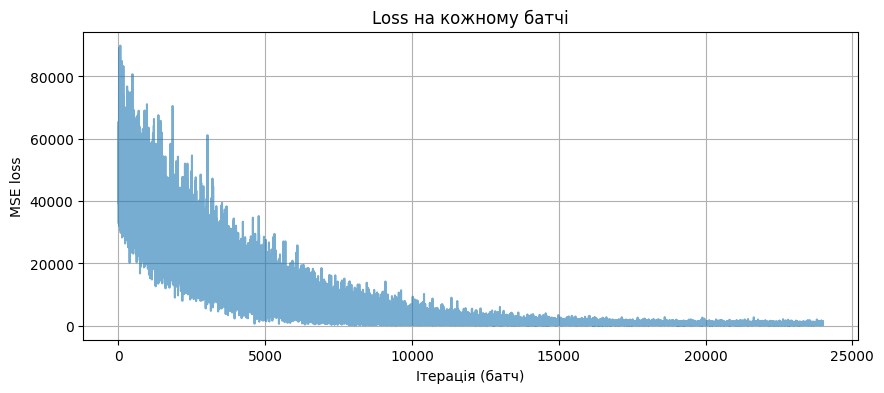

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(losses, alpha=0.6)
plt.xlabel("Ітерація (батч)")
plt.ylabel("MSE loss")
plt.title("Loss на кожному батчі")
plt.grid(True)
plt.show()

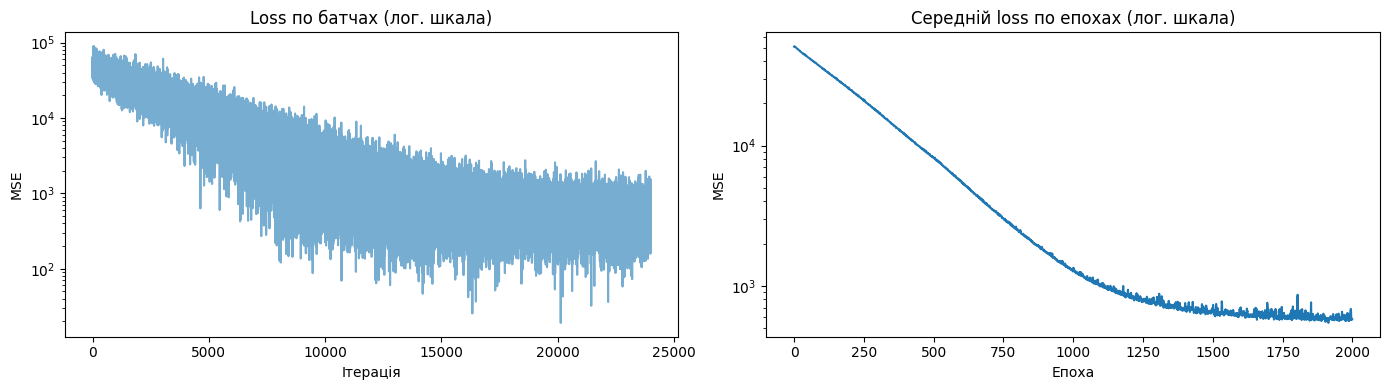

In [13]:
losses_arr = np.array(losses)
epoch_losses = losses_arr.reshape(n_epochs, -1).mean(axis=1)  # 2000 x 12 -> по епохах

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(losses_arr, alpha=0.6)
axes[0].set_yscale("log")
axes[0].set_title("Loss по батчах (лог. шкала)")
axes[0].set_xlabel("Ітерація")
axes[0].set_ylabel("MSE")

axes[1].plot(epoch_losses)
axes[1].set_yscale("log")
axes[1].set_title("Середній loss по епохах (лог. шкала)")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("MSE")

plt.tight_layout()
plt.show()

Оптимізація та збіжність досягнуті: loss впав майже на два порядки (з ~5·10⁴ до ~6·10²), вийшов на плато і не росте. Тобто модель навчилась відображати «значення в попередньому місяці → значення в наступному» на тренувальних даних.

Але графік loss каже лише про тренувальну вибірку. Test RMSE ≈ 103 означає, що  модель добре підігналась під train (RMSE ≈ 24), а на новіших даних помилка в ~4 рази більша, тобто узагальнення слабке. Головна причина, найімовірніше, тренд: у тесті значення вищі за все, що модель бачила в тренуванні.

Модель навчилась, але не факт, що точно)

Доволі неочікувано, що середньоквадратичне відхилення тестового набору даних буде на порядок більшим за одиниці в нашому наборі даних. Середньоквадратичне відхилення 100 означає, що прогноз і фактичне значення будуть відрізнятися в середньому на 100 (тобто, 100 000 пасажирів у цьому наборі даних).



Щоб краще зрозуміти якість прогнозу, ви можете побудувати графік з кодом нижче (а ще нижче - описано, що відбувається в цьому коді, бо це теж корисно зрозуміти):

/tmp/ipykernel_6245/3971159290.py:7: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  train_plot[lookback:train_size] = model(X_train)[:, -1]
/tmp/ipykernel_6245/3971159290.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  test_plot[train_size+lookback:len(data)] = model(X_test)[:, -1]


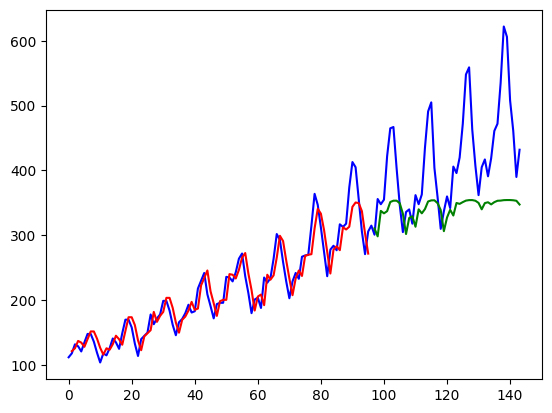

In [15]:
def plot_predicts():
  with torch.no_grad():
      # Зсув прогнозів для тренувальних даних
      train_plot = np.ones_like(data) * np.nan
      y_pred = model(X_train)
      y_pred = y_pred[:, -1]
      train_plot[lookback:train_size] = model(X_train)[:, -1]

      # Зсув прогнозів для тестових даних
      test_plot = np.ones_like(data) * np.nan
      test_plot[train_size+lookback:len(data)] = model(X_test)[:, -1]

  # Візуалізація результатів
  plt.plot(data, c='b')  # Реальні дані
  plt.plot(train_plot, c='r')  # Прогнози на тренувальних даних
  plt.plot(test_plot, c='g')   # Прогнози на тестових даних
  plt.show()

plot_predicts()

**Що відбувається в коді вище.** В цьому коді здійснюється процес прогнозування часових рядів за допомогою LSTM моделі, а також виведення графіку, який показує реальні значення, тренувальні та тестові прогнози. Ось що відбувається на кожному етапі:

1. **`torch.no_grad()`**: Цей контекстний менеджер вимикає обчислення градієнтів, що означає, що під час прогнозування не будуть зберігатися проміжні обчислення для зворотного проходу (backpropagation). Це підвищує ефективність під час прогнозування і зменшує використання пам'яті.

2. **Зсув прогнозів для тренувальних даних:**
   - Створюється масив `train_plot`, який має такий самий розмір, як і часовий ряд (`timeseries`), і заповнюється значеннями NaN (`np.nan`), щоб залишити місце для реальних значень.
   - Модель передбачає виходи для тренувальних даних `X_train`.
   - Використовується лише останнє передбачене значення для кожного входу LSTM (`y_pred[:, -1]`).
   - Прогнози зсуваються, починаючи з індексу `lookback` до кінця тренувальних даних (індекс `train_size`). Цей зсув потрібен, щоб зробити прогноз на основі попередніх даних і відобразити його на правильній частині графіку.

3. **Зсув прогнозів для тестових даних:**
   - Створюється масив `test_plot`, який також заповнюється NaN.
   - Прогнози для тестових даних додаються з індексу `train_size + lookback` до кінця реальних даних, щоб відобразити, де модель починає прогнозувати тестову вибірку.

4. **Побудова графіка:**
   - `plt.plot(timeseries, c='b')`: Виводить реальні значення часового ряду (синя лінія).
   - `plt.plot(train_plot, c='r')`: Виводить тренувальні прогнози (червона лінія).
   - `plt.plot(test_plot, c='g')`: Виводить тестові прогнози (зелена лінія).

**Чому це робиться:**
- Зсув прогнозів для тренувальних і тестових даних дозволяє візуально зрівняти, наскільки добре модель прогнозує як на тренувальній, так і на тестовій вибірках. Зазвичай, червона лінія (тренувальні прогнози) повинна точно відповідати синій лінії (реальні дані), а зелена лінія (тестові прогнози) дає змогу побачити, наскільки модель добре працює на нових даних, яких вона раніше не бачила.

Модель не вловила тренд на нових даних. Реальний ряд у 1957-1960 роках піднімається вище, ніж будь-що в тренуванні (максимум там близько 350-400), а прогноз упирається в діапазон, який модель бачила. Тому помилка на тесті має переважно характер систематичного зміщення вниз, і вона зростає разом з рівнем ряду: найгірше на піках 1959-1960 років, де недооцінка сягає 150-250 тисяч пасажирів. Це пояснює test RMSE ≈ 103.

**Завдання 8**. Навчіть модель з hidden_size=100 та порівняйте результати прогнозів з попередніми.

In [16]:
def train_model(hidden_size, num_layers=1, n_epochs=2000, seed=42):
    torch.manual_seed(seed)
    model = AirModel(hidden_size=hidden_size, num_layers=num_layers)
    optimizer = optim.Adam(model.parameters())
    loss_fn = nn.MSELoss()
    losses = []

    for epoch in range(n_epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            loss = loss_fn(model(X_batch), y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

        if epoch % 100 == 0:
            model.eval()
            with torch.no_grad():
                train_rmse = torch.sqrt(loss_fn(model(X_train), y_train)).item()
                test_rmse = torch.sqrt(loss_fn(model(X_test), y_test)).item()
            print(f"Epoch {epoch}: train RMSE {train_rmse:.4f}, test RMSE {test_rmse:.4f}")
    return model, losses

model_100, losses_100 = train_model(hidden_size=100)

Epoch 0: train RMSE 225.6851, test RMSE 422.0886
Epoch 100: train RMSE 149.1595, test RMSE 340.7379
Epoch 200: train RMSE 100.5174, test RMSE 282.5364
Epoch 300: train RMSE 71.3959, test RMSE 239.0329
Epoch 400: train RMSE 51.2334, test RMSE 202.3426
Epoch 500: train RMSE 38.6880, test RMSE 172.9250
Epoch 600: train RMSE 31.3156, test RMSE 149.6934
Epoch 700: train RMSE 27.8044, test RMSE 132.0734
Epoch 800: train RMSE 25.3218, test RMSE 118.4700
Epoch 900: train RMSE 24.7987, test RMSE 108.8834
Epoch 1000: train RMSE 23.9240, test RMSE 102.8427
Epoch 1100: train RMSE 25.1596, test RMSE 97.9929
Epoch 1200: train RMSE 23.4186, test RMSE 96.0914
Epoch 1300: train RMSE 23.3954, test RMSE 92.3424
Epoch 1400: train RMSE 24.2267, test RMSE 89.0208
Epoch 1500: train RMSE 25.1885, test RMSE 92.5843
Epoch 1600: train RMSE 23.7122, test RMSE 86.4070
Epoch 1700: train RMSE 25.2351, test RMSE 87.4286
Epoch 1800: train RMSE 23.2397, test RMSE 85.6443
Epoch 1900: train RMSE 23.1399, test RMSE 84.919

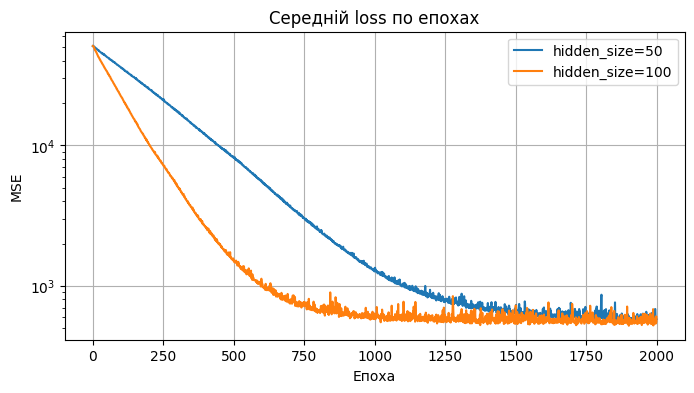

hidden=50: train RMSE 23.42, test RMSE 100.69
hidden=100: train RMSE 23.69, test RMSE 85.55


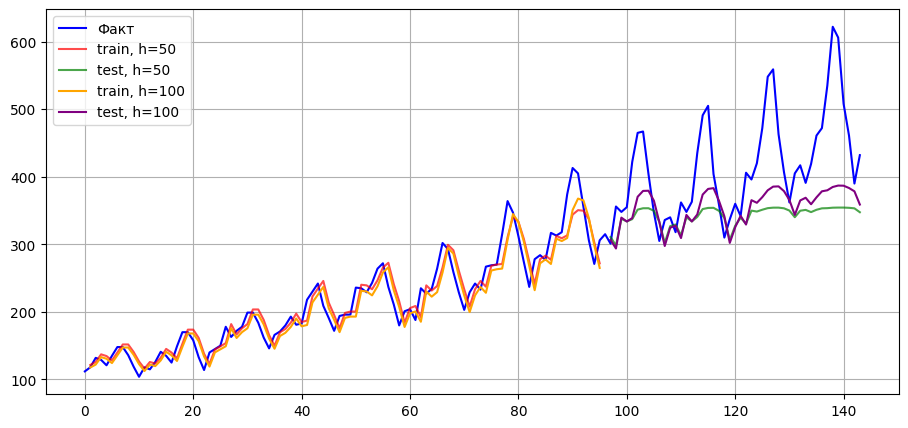

In [17]:
# 1. Порівняння loss по епохах
ep50 = np.array(losses).reshape(n_epochs, -1).mean(axis=1)
ep100 = np.array(losses_100).reshape(n_epochs, -1).mean(axis=1)

plt.figure(figsize=(8, 4))
plt.plot(ep50, label="hidden_size=50")
plt.plot(ep100, label="hidden_size=100")
plt.yscale("log"); plt.xlabel("Епоха"); plt.ylabel("MSE"); plt.legend(); plt.grid(True)
plt.title("Середній loss по епохах")
plt.show()

# 2. Фінальні RMSE обох моделей
def rmse(m, X, y):
    m.eval()
    with torch.no_grad():
        return torch.sqrt(nn.functional.mse_loss(m(X), y)).item()

for name, m in [("hidden=50", model), ("hidden=100", model_100)]:
    print(f"{name}: train RMSE {rmse(m, X_train, y_train):.2f}, "
          f"test RMSE {rmse(m, X_test, y_test):.2f}")

# 3. Прогнози на одному графіку
def make_plots(m):
    m.eval()
    with torch.no_grad():
        p_train = m(X_train)[:, 0].numpy()
        p_test = m(X_test)[:, 0].numpy()
    tr = np.full(len(data), np.nan); te = np.full(len(data), np.nan)
    tr[lookback:train_size] = p_train
    te[train_size + lookback:] = p_test
    return tr, te

tr50, te50 = make_plots(model)
tr100, te100 = make_plots(model_100)

plt.figure(figsize=(11, 5))
plt.plot(data, c="b", label="Факт")
plt.plot(tr50, c="r", alpha=0.7, label="train, h=50")
plt.plot(te50, c="g", alpha=0.7, label="test, h=50")
plt.plot(tr100, c="orange", label="train, h=100")
plt.plot(te100, c="purple", label="test, h=100")
plt.legend(); plt.grid(True)
plt.show()

Більша ємність (h=100) дає швидшу збіжність і частково відновлює сезонність на тесті, хоча в порівнянні це один запуск. Але фундаментальне обмеження лишається: значення тесту виходять за діапазон тренування, а модель із lookback=1 отримує на вході лише одне число й не бачить ні тренду, ні сезонної фази. Тому «стеля» зсунулась вгору, але не зникла.

Спільна проблема: обидві моделі недооцінюють піки 1959-1960 років на 150-250 тисяч пасажирів. Прогноз росте повільніше за факт, тобто тренд екстраполюється погано.

##Висновок.
Збільшення hidden_size зі 50 до 100 прискорило навчання вдвічі і покращило test RMSE з ≈103 до ≈85, не погіршивши train. Проте помилка на тесті (~85) і далі порівнянна зі стандартним відхиленням тестової частини ряду, тож головну проблему (екстраполяція тренду та lookback=1) збільшення ємності не усуває, а лише трохи пом'якшує. Радикального покращення варто чекати від логарифму/приростів, масштабування та більшого lookback.